# CNNs in Practice with PyTorch — an in-depth notebook

| # | Topic | # | Topic |
|---|---|---|---|
| 1 | Image tensors, channels, normalization and batching | 6 | Frozen backbone vs fine-tuning |
| 2 | Convolution, filters, stride, padding and pooling | 7 | Pretrained weights and inference transforms |
| 3 | CNN feature hierarchies | 8 | Validation and class-wise evaluation |
| 4 | Data augmentation and image preprocessing | 9 | GPU memory and batch-size trade-offs |
| 5 | Transfer learning vs training from scratch | 10 | Dataset licensing and image privacy |

**Running examples**
* Two colour photos bundled with scikit-learn (`china.jpg`, `flower.jpg`) for preprocessing and filters.
* **Shapes**, a dataset generated in the notebook: 32 × 32 colour images of 8 shapes with random size, position, colours and noise.
  * **Source task** — circle, square, triangle, plus — 1,000 images per class (lots of data)
  * **Target task** — ring, diamond, dash, x — only **5 or 20 labelled images per class** (little data, like most real projects)

  Training on the source task and transferring to the target task lets us run real transfer-learning experiments on a CPU in seconds.
* A **ResNet-18** from torchvision for pretrained-weight metadata, inference transforms and memory estimates.

Every section: **concept → code → real output → 🔍 what to notice → ✍️ exercise**. All figures are also saved to `figs/`.

## 0. Setup, helpers and data

In [1]:
import math, time, copy, json, io, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
import torchvision
from torchvision.transforms import v2
from sklearn.datasets import load_sample_image
from sklearn.metrics import confusion_matrix, classification_report

SEED = 0
torch.manual_seed(SEED); np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
FIGS = Path("figs"); FIGS.mkdir(exist_ok=True)
RESULTS = {}                      # numbers we collect along the way
plt.rcParams["figure.dpi"] = 90
print(f"Python {platform.python_version()} | PyTorch {torch.__version__} | torchvision {torchvision.__version__} | device {device}")

def save_show(name):
    plt.savefig(FIGS / f"{name}.png", dpi=110, bbox_inches="tight"); plt.show()

def show(images, titles=None, cols=None, size=2.6, name=None, cmap="gray"):
    images = list(images); cols = cols or len(images); rows = math.ceil(len(images) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows))
    axes = np.atleast_1d(axes).ravel()
    for i, ax in enumerate(axes):
        ax.axis("off")
        if i >= len(images): continue
        img = images[i].detach().cpu()
        if img.ndim == 3 and img.shape[0] == 3: ax.imshow(img.permute(1, 2, 0).clamp(0, 1).numpy())
        else: ax.imshow(img.squeeze().numpy(), cmap=cmap)
        if titles: ax.set_title(titles[i], fontsize=9)
    plt.tight_layout()
    save_show(name) if name else plt.show()

Python 3.13.18 | PyTorch 2.15.0+cu132 | torchvision 0.29.2+cu132 | device cpu


source train (4000, 3, 32, 32) | target train (20/class) (80, 3, 32, 32) | target val (800, 3, 32, 32)


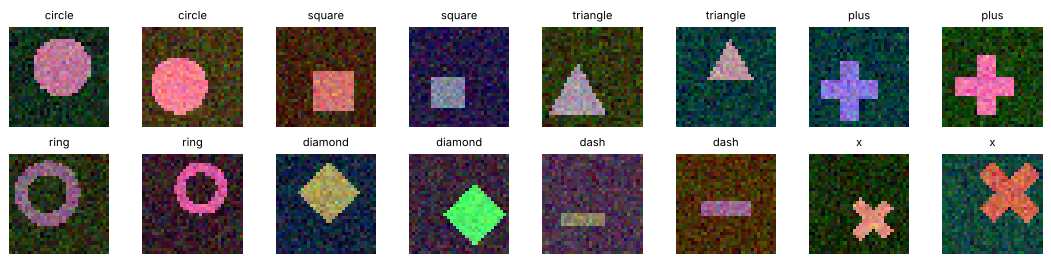

In [2]:
SHAPES = ["circle", "square", "triangle", "plus", "ring", "diamond", "dash", "x"]

def make_shapes(kind, n, size=32, g=None):
    # n random coloured images of one shape: random centre, size, foreground/background colour and noise
    yy, xx = torch.meshgrid(torch.arange(size).float(), torch.arange(size).float(), indexing="ij")
    out = torch.zeros(n, 3, size, size)
    for i in range(n):
        cx, cy = (torch.rand(2, generator=g) * 12 + 10).tolist()
        r = (torch.rand(1, generator=g) * 5 + 6).item()
        dx, dy = xx - cx, yy - cy
        if kind == "circle":     m = dx**2 + dy**2 <= r**2
        elif kind == "square":   m = (dx.abs() <= .85*r) & (dy.abs() <= .85*r)
        elif kind == "triangle": m = (dy <= .8*r) & (dy >= -.9*r + 1.8*dx.abs())
        elif kind == "plus":     m = ((dx.abs() <= .3*r) & (dy.abs() <= r)) | ((dy.abs() <= .3*r) & (dx.abs() <= r))
        elif kind == "ring":     d = (dx**2 + dy**2).sqrt(); m = (d <= r) & (d >= .6*r)
        elif kind == "diamond":  m = dx.abs() + dy.abs() <= r
        elif kind == "dash":     m = (dx.abs() <= r) & (dy.abs() <= .3*r)
        elif kind == "x":
            u, v = (dx + dy) / math.sqrt(2), (dx - dy) / math.sqrt(2)
            m = ((u.abs() <= .3*r) & (v.abs() <= r)) | ((v.abs() <= .3*r) & (u.abs() <= r))
        fg = torch.rand(3, generator=g) * .7 + .3; bg = torch.rand(3, generator=g) * .3
        img = bg.view(3, 1, 1).expand(3, size, size).clone()
        img[:, m] = fg.view(3, 1)
        out[i] = (img + .08 * torch.randn(3, size, size, generator=g)).clamp(0, 1)
    return out

def shapes_dataset(classes, n_per_class, seed):
    g = torch.Generator().manual_seed(seed)
    X = torch.cat([make_shapes(c, n_per_class, g=g) for c in classes])
    y = torch.arange(len(classes)).repeat_interleave(n_per_class)
    return X, y

SRC, TGT = SHAPES[:4], SHAPES[4:]
Xs, ys   = shapes_dataset(SRC, 1000, seed=1)     # source train: 4,000 images
Xsv, ysv = shapes_dataset(SRC, 200, seed=2)      # source val
Xt20, yt20 = shapes_dataset(TGT, 20, seed=3)     # target train: only 20 per class
Xt5, yt5   = shapes_dataset(TGT, 5, seed=3)      # target train: only 5 per class
Xtv, ytv   = shapes_dataset(TGT, 200, seed=4)    # target val: 200 per class
print("source train", tuple(Xs.shape), "| target train (20/class)", tuple(Xt20.shape), "| target val", tuple(Xtv.shape))

g = torch.Generator().manual_seed(7)
gallery = [make_shapes(s, 2, g=g) for s in SHAPES]
show([gallery[i // 2][i % 2] for i in range(16)], [SHAPES[i // 2] for i in range(16)], cols=8, size=1.5, name="shapes_gallery")

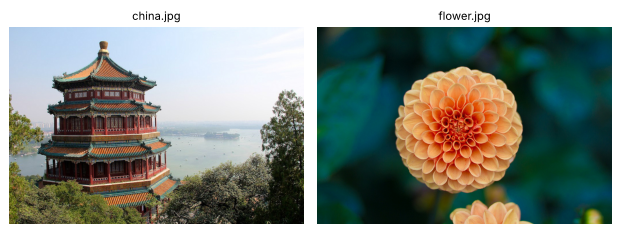

In [3]:
china  = torch.from_numpy(load_sample_image("china.jpg").copy()).permute(2, 0, 1).float() / 255
flower = torch.from_numpy(load_sample_image("flower.jpg").copy()).permute(2, 0, 1).float() / 255
show([china, flower], ["china.jpg", "flower.jpg"], size=3.5)

In [4]:
class SmallCNN(nn.Module):
    # 3 conv blocks (conv → BN → ReLU → max-pool) + global-average-pool head
    def __init__(self, n_classes=4):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 16), block(16, 32), block(32, 64))      # 32→16→8→4
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, n_classes))
    def forward(self, x):
        return self.head(self.features(x))

MEAN = Xs.mean(dim=(0, 2, 3)); STD = Xs.std(dim=(0, 2, 3))     # per-channel stats of the SOURCE training set
def normalize(x): return (x - MEAN.view(1, 3, 1, 1)) / STD.view(1, 3, 1, 1)

def evaluate(model, X, y, bs=256):
    model.eval(); preds = []
    with torch.inference_mode():
        for i in range(0, len(X), bs):
            preds.append(model(normalize(X[i:i+bs]).to(device)).argmax(1).cpu())
    p = torch.cat(preds)
    return (p == y).float().mean().item(), p

def train(model, X, y, Xv=None, yv=None, epochs=10, lr=1e-3, bs=32, seed=0, aug=None,
          param_groups=None, frozen_features=False, log_every=0):
    torch.manual_seed(seed)
    model.to(device)
    params = param_groups if param_groups is not None else [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.Adam(params, lr=lr)
    hist = []
    for ep in range(1, epochs + 1):
        model.train()
        if frozen_features: model.features.eval()      # keep frozen BatchNorm statistics fixed
        perm = torch.randperm(len(y)); total = 0.0
        for i in range(0, len(y), bs):
            idx = perm[i:i+bs]; xb = X[idx]
            if aug is not None: xb = aug(xb)
            loss = F.cross_entropy(model(normalize(xb).to(device)), y[idx].to(device))
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(idx)
        row = {"epoch": ep, "train_loss": total / len(y)}
        if Xv is not None: row["val_acc"] = evaluate(model, Xv, yv)[0]
        hist.append(row)
        if log_every and (ep == 1 or ep % log_every == 0): print(row)
    return pd.DataFrame(hist).set_index("epoch")

def n_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if (p.requires_grad or not trainable_only))
print("SmallCNN parameters:", n_params(SmallCNN()))

SmallCNN parameters: 24068


---
## 1. Image tensors, channels, normalization and batching

| | Shape | Notes |
|---|---|---|
| One image from a file | `(H, W, C)` uint8 0–255 | NumPy / PIL layout |
| One image in PyTorch | `(C, H, W)` float32 0–1 | `permute(2, 0, 1)`, `/ 255` |
| A batch | `(N, C, H, W)` | what every `nn.Conv2d` expects |

**Normalization** rescales each channel to mean ≈ 0, std ≈ 1: `x' = (x − mean_c) / std_c`. It makes optimisation easier and is
**required** to match what a pretrained model saw during training. Compute the statistics on the **training set only**.

one photo  : (3, 427, 640) torch.float32
one shape  : (3, 32, 32)
a batch    : (32, 3, 32, 32)  ← (N, C, H, W)

per-channel mean of source train set: [0.241 0.242 0.24 ]
per-channel std  of source train set: [0.23  0.228 0.23 ]
after normalize → mean [0.007 0.003 0.011]  std [0.987 1.008 0.996]


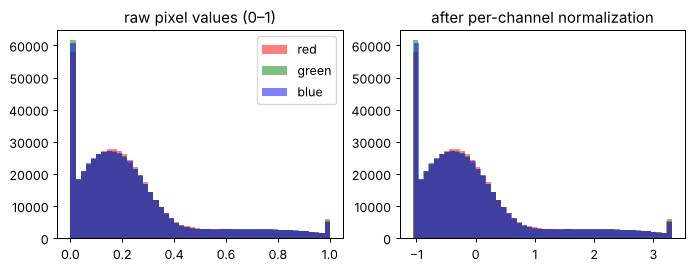

In [5]:
print("one photo  :", tuple(china.shape), china.dtype)
print("one shape  :", tuple(Xs[0].shape))
print("a batch    :", tuple(Xs[:32].shape), " ← (N, C, H, W)")
print("\nper-channel mean of source train set:", MEAN.numpy().round(3))
print("per-channel std  of source train set:", STD.numpy().round(3))
sample = Xs[torch.randperm(len(Xs), generator=torch.Generator().manual_seed(0))[:512]]   # random mix of classes
xn = normalize(sample)
print("after normalize → mean", xn.mean((0, 2, 3)).numpy().round(3), " std", xn.std((0, 2, 3)).numpy().round(3))

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for c, col in enumerate(["red", "green", "blue"]):
    axes[0].hist(sample[:, c].flatten().numpy(), bins=50, alpha=.5, color=col, label=col)
    axes[1].hist(xn[:, c].flatten().numpy(), bins=50, alpha=.5, color=col)
axes[0].set_title("raw pixel values (0–1)"); axes[1].set_title("after per-channel normalization"); axes[0].legend()
save_show("normalization_hist")

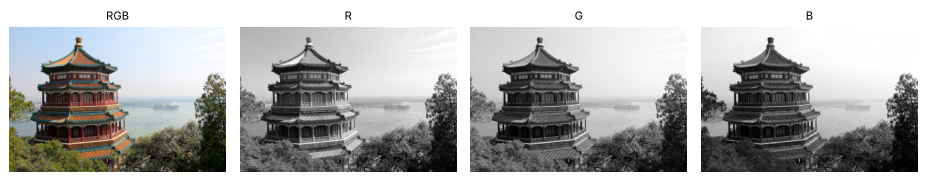

sizes: [(3, 427, 640), (3, 300, 400), (3, 350, 200)]
torch.stack fails: stack expects each tensor to be equal size, but got [3, 427, 640] at e …
after Resize(160) + CenterCrop(144): (3, 3, 144, 144)


In [6]:
# Channels are separate images; batching needs equal sizes
show([china, china[0], china[1], china[2]], ["RGB", "R", "G", "B"], size=2.6, name="channels")

photos = [china, flower[:, :300, :400], china[:, 50:400, 100:300]]          # three different sizes
print("sizes:", [tuple(p.shape) for p in photos])
try:
    torch.stack(photos)
except RuntimeError as e:
    print("torch.stack fails:", str(e)[:70], "…")
prep = v2.Compose([v2.Resize(160, antialias=True), v2.CenterCrop(144)])
batch = torch.stack([prep(p) for p in photos])
print("after Resize(160) + CenterCrop(144):", tuple(batch.shape))

In [7]:
# DataLoader does the batching for us
loader = DataLoader(TensorDataset(Xs, ys), batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(0))
xb, yb = next(iter(loader))
print("batch:", tuple(xb.shape), xb.dtype, "| labels:", tuple(yb.shape), yb.dtype, "| batches per epoch:", len(loader))
print("memory of one float32 batch:", f"{xb.numel() * 4 / 1024:.0f} KB")

batch: (64, 3, 32, 32) torch.float32 | labels: (64,) torch.int64 | batches per epoch: 63
memory of one float32 batch: 768 KB


🔍 **What to notice**
* Our shapes have a dark background, so the raw channel means are low (~0.2). After normalization every channel has mean ≈ 0, std ≈ 1.
* Images of different sizes can't be stacked: resize + crop (or pad) to a common size first.
* A batch of 64 small 32×32 images is only ~0.8 MB; a batch of 64 photos at 224×224 is ~38 MB *before* any activations (Section 9).

✍️ **Exercise 1:** Compute the mean/std of `flower` per channel and normalize it. Then **un-normalize** it back and check you get the original.

---
## 2. Convolution, filters, stride, padding and pooling

A conv layer slides `C_out` learnable **filters** (each `C_in × k × k`) over the input.

**Output size:** `out = ⌊(n + 2·padding − dilation·(k − 1) − 1) / stride⌋ + 1`

| Setting | Effect |
|---|---|
| **kernel k** | size of the neighbourhood each output sees |
| **stride s** | step size — `s = 2` halves height and width |
| **padding p** | border added — `p = k // 2` keeps the size (“same”) |
| **dilation d** | gaps inside the kernel — wider view, same parameters |
| **pooling** | max (keep strongest response) or average, usually 2×2 stride 2 |

In [8]:
def out_size(n, k, s=1, p=0, d=1): return (n + 2*p - d*(k - 1) - 1) // s + 1
rows = []
for n, k, s, p, d in [(32, 3, 1, 0, 1), (32, 3, 1, 1, 1), (32, 3, 2, 1, 1), (32, 5, 1, 2, 1), (32, 3, 1, 2, 2), (224, 7, 2, 3, 1)]:
    conv = nn.Conv2d(3, 8, k, stride=s, padding=p, dilation=d)
    actual = conv(torch.zeros(1, 3, n, n)).shape[-1]
    rows.append(dict(input=n, kernel=k, stride=s, padding=p, dilation=d, formula=out_size(n, k, s, p, d), pytorch=actual))
pd.DataFrame(rows)

,input,kernel,stride,padding,dilation,formula,pytorch
0,32,3,1,0,1,30,30
1,32,3,1,1,1,32,32
2,32,3,2,1,1,16,16
3,32,5,1,2,1,32,32
4,32,3,1,2,2,32,32
5,224,7,2,3,1,112,112


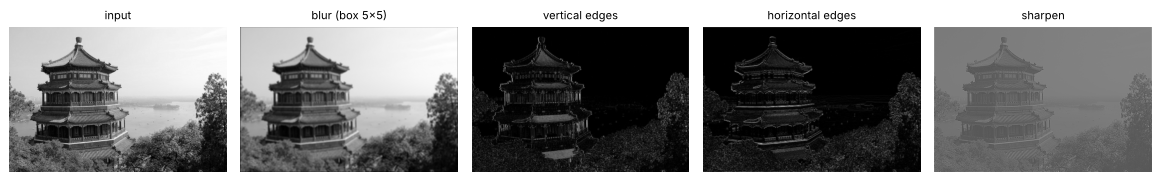

In [9]:
# Hand-made filters applied with F.conv2d to a real photo
gray = (china * torch.tensor([.299, .587, .114]).view(3, 1, 1)).sum(0, keepdim=True).unsqueeze(0)   # (1,1,H,W)
kernels = {
    "blur (box 5×5)":     torch.ones(5, 5) / 25,
    "vertical edges":     torch.tensor([[-1., 0, 1], [-2, 0, 2], [-1, 0, 1]]),
    "horizontal edges":   torch.tensor([[-1., -2, -1], [0, 0, 0], [1, 2, 1]]),
    "sharpen":            torch.tensor([[0., -1, 0], [-1, 5, -1], [0, -1, 0]]),
}
outs = [F.conv2d(gray, k.view(1, 1, *k.shape), padding=k.shape[-1] // 2)[0] for k in kernels.values()]
show([gray[0]] + [o.abs() if "edges" in n else o for o, n in zip(outs, kernels)], ["input"] + list(kernels), cols=5, size=2.6, name="filters")

stride 1, pad 1  → (427, 640)
stride 2, pad 1  → (214, 320)
stride 4, pad 1  → (107, 160)
no padding       → (425, 638)


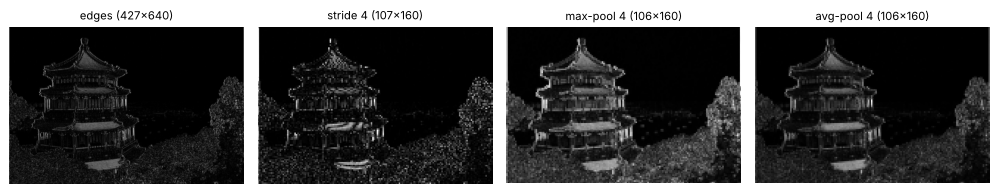

In [10]:
# Stride, padding and pooling on the same image
k = kernels["vertical edges"].view(1, 1, 3, 3)
variants = {
    "stride 1, pad 1": F.conv2d(gray, k, stride=1, padding=1),
    "stride 2, pad 1": F.conv2d(gray, k, stride=2, padding=1),
    "stride 4, pad 1": F.conv2d(gray, k, stride=4, padding=1),
    "no padding":      F.conv2d(gray, k, padding=0),
}
for n_, o in variants.items(): print(f"{n_:16s} → {tuple(o.shape[-2:])}")
edges = variants["stride 1, pad 1"].abs()
pooled = {"max-pool 4×4": F.max_pool2d(edges, 4), "avg-pool 4×4": F.avg_pool2d(edges, 4)}
show([edges[0], variants["stride 4, pad 1"].abs()[0], pooled["max-pool 4×4"][0], pooled["avg-pool 4×4"][0]],
     ["edges (427×640)", "stride 4 (107×160)", "max-pool 4 (106×160)", "avg-pool 4 (106×160)"], cols=4, size=2.8, name="stride_pool")

In [11]:
# Why convolutions? Parameter count for a 224×224×3 input
dense = nn.Linear(224 * 224 * 3, 64)
conv = nn.Conv2d(3, 64, 3, padding=1)
print(f"Dense layer to 64 units : {n_params(dense):>12,} parameters")
print(f"Conv 3×3 with 64 filters: {n_params(conv):>12,} parameters")
print(f"ratio: {n_params(dense) / n_params(conv):,.0f}× fewer for the conv — weights are SHARED across positions")
RESULTS["params_dense"], RESULTS["params_conv"] = n_params(dense), n_params(conv)

Dense layer to 64 units :    9,633,856 parameters
Conv 3×3 with 64 filters:        1,792 parameters
ratio: 5,376× fewer for the conv — weights are SHARED across positions


🔍 **What to notice**
* The formula and PyTorch agree for every setting. `padding = k // 2` with stride 1 keeps the size; stride 2 halves it.
* The same 3×3 edge filter finds vertical edges anywhere — **weight sharing** + **locality** are why CNNs suit images.
* Max-pooling keeps the strongest edges (crisp); average-pooling smooths them (dimmer).
* A conv layer needs ~5,400× fewer parameters than a dense layer on the same image.

✍️ **Exercise 2:** What output size does `Conv2d(k=3, stride=2, padding=0)` give on 225×225? Check with the formula, then in PyTorch.

---
## 3. CNN feature hierarchies

Stacked conv layers build a **hierarchy**: early layers detect edges and colours; middle layers combine them into corners and
textures; deep layers respond to object parts and whole shapes. Each layer also sees a larger patch of the input — its **receptive field**.

We train `SmallCNN` on the **source task** (4 shapes, 4,000 images), then look inside.

In [12]:
torch.manual_seed(0)
source_model = SmallCNN(4)
t0 = time.time()
h_src = train(source_model, Xs, ys, Xsv, ysv, epochs=10, lr=1e-3, bs=32, log_every=2)
print(f"trained in {time.time() - t0:.0f} s | final source val accuracy: {h_src.val_acc.iloc[-1]:.3f}")
RESULTS["source_val_acc"] = h_src.val_acc.iloc[-1]
torch.save(source_model.state_dict(), "source_model.pt")

{'epoch': 1, 'train_loss': 0.596188307106495, 'val_acc': 0.9975000023841858}


{'epoch': 2, 'train_loss': 0.1115043713748455, 'val_acc': 0.9937499761581421}


{'epoch': 4, 'train_loss': 0.03390078138560057, 'val_acc': 0.9487500190734863}


{'epoch': 6, 'train_loss': 0.017537543019279837, 'val_acc': 1.0}


{'epoch': 8, 'train_loss': 0.008425016984343529, 'val_acc': 1.0}


{'epoch': 10, 'train_loss': 0.005697629722300917, 'val_acc': 1.0}
trained in 15 s | final source val accuracy: 1.000


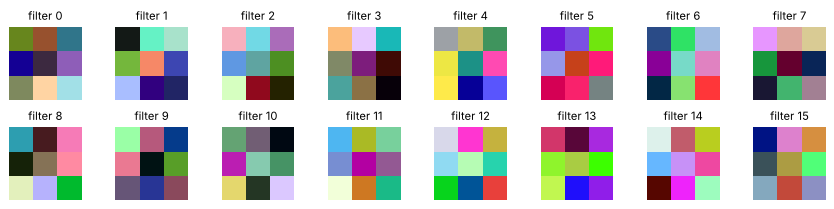

In [13]:
# Layer 1 filters: 16 learned 3×3 RGB kernels
w = source_model.features[0][0].weight.detach().cpu()          # (16, 3, 3, 3)
w = (w - w.amin(dim=(1, 2, 3), keepdim=True)) / (w.amax(dim=(1, 2, 3), keepdim=True) - w.amin(dim=(1, 2, 3), keepdim=True))
show(list(w), [f"filter {i}" for i in range(16)], cols=8, size=1.2, name="layer1_filters")

block 1: (16, 16, 16)  (channels, height, width)
block 2: (32, 8, 8)  (channels, height, width)
block 3: (64, 4, 4)  (channels, height, width)


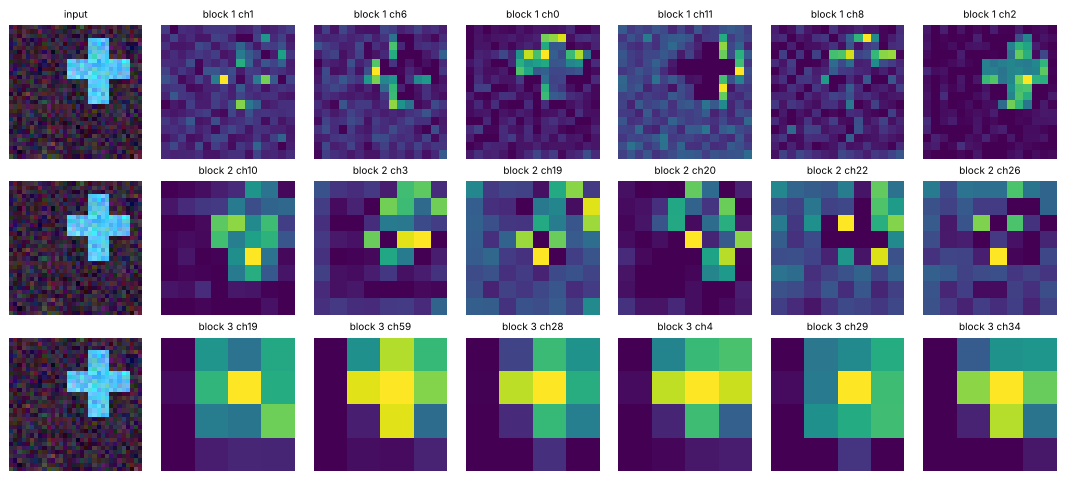

In [14]:
# Feature maps at each depth for one image
img = Xsv[ysv == 3][0]                                              # a "plus"
acts = {}
x = normalize(img.unsqueeze(0)).to(device)
source_model.eval()
with torch.inference_mode():
    for i, block in enumerate(source_model.features):
        x = block(x); acts[f"block {i+1}"] = x[0].cpu()
for name, a in acts.items(): print(f"{name}: {tuple(a.shape)}  (channels, height, width)")
fig, axes = plt.subplots(3, 7, figsize=(12, 5.4))
for row, (name, a) in enumerate(acts.items()):
    axes[row, 0].imshow(img.permute(1, 2, 0)); axes[row, 0].set_title("input" if row == 0 else "", fontsize=8)
    top = a.flatten(1).mean(1).argsort(descending=True)[:6]
    for j, ch in enumerate(top):
        axes[row, j + 1].imshow(a[ch], cmap="viridis"); axes[row, j + 1].set_title(f"{name} ch{ch.item()}", fontsize=8)
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); save_show("feature_maps")

In [15]:
# Receptive field: how much of the input one unit sees
def receptive_fields(layers):
    rf, jump, rows = 1, 1, []
    for name, k, s in layers:
        rf = rf + (k - 1) * jump; jump *= s
        rows.append(dict(layer=name, kernel=k, stride=s, receptive_field=f"{rf}×{rf}", step_between_units=jump))
    return pd.DataFrame(rows)
receptive_fields([("conv1", 3, 1), ("pool1", 2, 2), ("conv2", 3, 1), ("pool2", 2, 2), ("conv3", 3, 1), ("pool3", 2, 2)])

,layer,kernel,stride,receptive_field,step_between_units
0,conv1,3,1,3×3,1
1,pool1,2,2,4×4,2
2,conv2,3,1,8×8,2
3,pool2,2,2,10×10,4
4,conv3,3,1,18×18,4
5,pool3,2,2,22×22,8


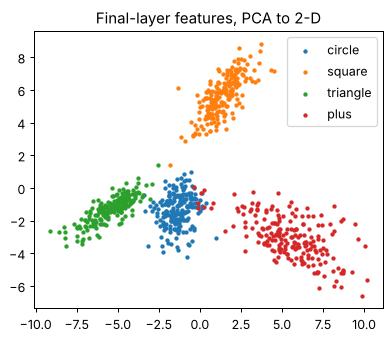

In [16]:
# Deep features separate the classes: 2-D projection (PCA) of the 64-d features
with torch.inference_mode():
    feats = source_model.head[:2](source_model.features(normalize(Xsv).to(device))).cpu()   # (800, 64)
fc = feats - feats.mean(0)
U, S, V = torch.pca_lowrank(fc, q=2)
proj = fc @ V[:, :2]
plt.figure(figsize=(5, 4))
for c in range(4):
    plt.scatter(proj[ysv == c, 0], proj[ysv == c, 1], s=6, label=SRC[c])
plt.legend(); plt.title("Final-layer features, PCA to 2-D"); save_show("feature_pca")

🔍 **What to notice**
* The source model reaches near-perfect validation accuracy — the shapes are learnable.
* Layer-1 filters look like small colour blobs and edge detectors — the same kind of filters we drew by hand in Section 2.
* Feature maps shrink (32→16→8→4) while channels grow (16→32→64): **less “where”, more “what”**.
* The receptive field grows from 3×3 to 22×22 pixels: block-3 units see most of the 32×32 image, so they can respond to whole shapes.
* In the 64-d final features, the four classes form separate clusters — that's what the last linear layer separates.

✍️ **Exercise 3:** Show feature maps for a *circle* and a *square*. Which block-3 channels respond differently?

---
## 4. Data augmentation and image preprocessing

**Preprocessing** (always, train *and* val): decode → resize/crop to the model size → to float → normalize.
**Augmentation** (training only): random, label-preserving changes that teach the model what *doesn't* matter.

| Augmentation | Teaches invariance to | Careful when |
|---|---|---|
| Random crop / resized crop | position, scale | the object could be cropped out |
| Horizontal flip | left–right | text, digits, road signs |
| Rotation | orientation | “6” vs “9”, medical laterality |
| Colour jitter | lighting, white balance | colour **is** the label |
| Blur / noise | camera quality | fine detail matters |

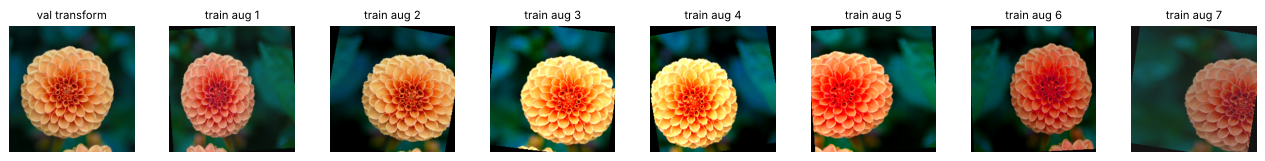

In [17]:
torch.manual_seed(0)
train_tf = v2.Compose([
    v2.RandomResizedCrop(224, scale=(0.4, 1.0), antialias=True),
    v2.RandomHorizontalFlip(),
    v2.RandomRotation(15),
    v2.ColorJitter(brightness=.3, contrast=.3, saturation=.3, hue=.04),
])
val_tf = v2.Compose([v2.Resize(256, antialias=True), v2.CenterCrop(224)])
show([val_tf(flower)] + [train_tf(flower) for _ in range(7)], ["val transform"] + [f"train aug {i+1}" for i in range(7)],
     cols=8, size=1.8, name="augment_photos")

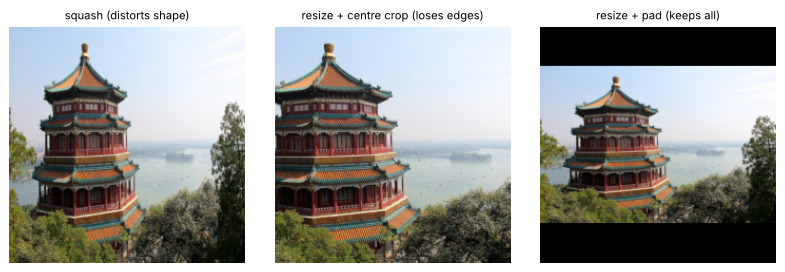

In [18]:
# Resizing choices: squash vs resize-shorter-side + centre crop vs pad
squash = v2.functional.resize(china, [224, 224], antialias=True)
crop = v2.functional.center_crop(v2.functional.resize(china, 224, antialias=True), [224, 224])
scale = 224 / max(china.shape[1:]); small = v2.functional.resize(china, [round(china.shape[1] * scale), 224], antialias=True)
padv = (224 - small.shape[1]); pad = F.pad(small, (0, 0, padv // 2, padv - padv // 2))
show([squash, crop, pad], ["squash (distorts shape)", "resize + centre crop (loses edges)", "resize + pad (keeps all)"], size=3, name="resize_choices")

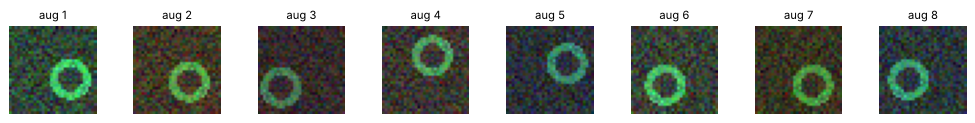

no augmentation   : val acc per seed [0.936 0.906 0.836] → mean 0.893


with augmentation : val acc per seed [0.976 0.961 0.975] → mean 0.971


In [19]:
# Does augmentation help with little data? Target task, 20 images per class, trained from scratch
def shape_augment(xb):
    n = len(xb)
    xb = torch.where((torch.rand(n) < .5).view(-1, 1, 1, 1), xb.flip(-1), xb)
    xb = torch.where((torch.rand(n) < .5).view(-1, 1, 1, 1), xb.flip(-2), xb)
    xb = torch.rot90(xb, int(torch.randint(0, 4, (1,))), (2, 3))
    sx, sy = torch.randint(-3, 4, (2,)).tolist(); xb = torch.roll(xb, (sy, sx), (2, 3))
    return (xb * (.7 + .6 * torch.rand(n, 3, 1, 1))).clamp(0, 1)            # brightness jitter per channel

g = torch.Generator().manual_seed(1)
show([shape_augment(Xt20[:1])[0] for _ in range(8)], [f"aug {i+1}" for i in range(8)], cols=8, size=1.4, name="augment_shapes")

aug_res = {}
for label, aug in [("no augmentation", None), ("with augmentation", shape_augment)]:
    accs = []
    for seed in [0, 1, 2]:
        torch.manual_seed(seed)
        h = train(SmallCNN(4), Xt20, yt20, Xtv, ytv, epochs=40, lr=1e-3, bs=16, seed=seed, aug=aug)
        accs.append(h.val_acc.iloc[-1])
    aug_res[label] = accs
    print(f"{label:18s}: val acc per seed {np.round(accs, 3)} → mean {np.mean(accs):.3f}")
RESULTS["augmentation"] = {k: [round(a, 4) for a in v] for k, v in aug_res.items()}

🔍 **What to notice**
* The validation transform is **deterministic** (resize + centre crop); training transforms are random every time.
* Squashing distorts shapes, centre-cropping can cut objects off, padding keeps everything but wastes pixels — choose per task.
* With only 80 training images, augmentation raises validation accuracy by several points on every seed: each epoch the model sees
  new variations, so it can't simply memorise.
* All our shapes look the same flipped or rotated, so those augmentations are safe here — that's a property of *this* data, not a rule.

✍️ **Exercise 4:** Remove one augmentation at a time from `shape_augment`. Which one matters most?

---
## 5. Transfer learning vs training from scratch

**From scratch:** random weights; the network must learn edges, textures and shapes from your data alone.
**Transfer learning:** start from a network trained on a big **source** task and adapt it to your **target** task.
Early features (edges, colours, corners) are general, so they transfer.

Experiment: target task = ring, diamond, dash, x, with **5** or **20** labelled images per class. Three strategies, three seeds each:
1. **scratch** — random init
2. **frozen** — source backbone frozen, train only a new final layer
3. **fine-tune** — source backbone + new final layer, all trained (small learning rate)

In [20]:
def make_transfer_model(mode):
    if mode == "scratch":
        return SmallCNN(4), dict(lr=1e-3)
    m = SmallCNN(4); m.load_state_dict(torch.load("source_model.pt"))
    m.head[-1] = nn.Linear(64, len(TGT))                     # new head for the 4 target classes
    if mode == "frozen":
        for p in m.features.parameters(): p.requires_grad = False
        return m, dict(lr=1e-2, frozen_features=True)
    if mode == "fine-tune":
        return m, dict(lr=1e-3)
    if mode == "fine-tune (discriminative LR)":
        groups = [{"params": m.features.parameters(), "lr": 1e-4}, {"params": m.head.parameters(), "lr": 1e-3}]
        return m, dict(lr=1e-3, param_groups=groups)

transfer = {}
curves = {}
t0 = time.time()
for n_per, (Xt, yt) in [(5, (Xt5, yt5)), (20, (Xt20, yt20))]:
    for mode in ["scratch", "frozen", "fine-tune"]:
        accs = []
        for seed in [0, 1, 2]:
            torch.manual_seed(seed)
            m, kw = make_transfer_model(mode)
            h = train(m, Xt, yt, Xtv, ytv, epochs=40, bs=16, seed=seed, **kw)
            accs.append(h.val_acc.iloc[-1])
            if seed == 0: curves[(n_per, mode)] = h.val_acc.tolist()
        transfer[(n_per, mode)] = accs
print(f"done in {time.time() - t0:.0f} s")
table = pd.DataFrame({f"{n} per class": {mode: f"{np.mean(transfer[(n, mode)]):.3f} ± {np.std(transfer[(n, mode)]):.3f}"
                                         for mode in ["scratch", "frozen", "fine-tune"]} for n in [5, 20]})
RESULTS["transfer"] = {f"{n}|{mode}": [round(a, 4) for a in v] for (n, mode), v in transfer.items()}
RESULTS["transfer_curves"] = {f"{n}|{mode}": [round(a, 4) for a in v] for (n, mode), v in curves.items()}
table

done in 86 s


,5 per class,20 per class
scratch,0.451 ± 0.059,0.893 ± 0.042
frozen,0.818 ± 0.026,0.896 ± 0.010
fine-tune,0.784 ± 0.028,0.970 ± 0.008


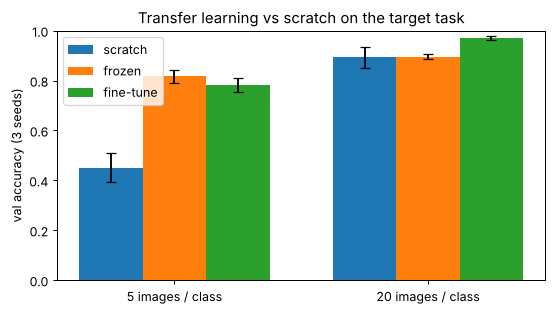

In [21]:
fig, ax = plt.subplots(figsize=(7, 3.6))
modes = ["scratch", "frozen", "fine-tune"]; xs = np.arange(2); w_ = .25
for i, mode in enumerate(modes):
    means = [np.mean(transfer[(n, mode)]) for n in [5, 20]]; stds = [np.std(transfer[(n, mode)]) for n in [5, 20]]
    ax.bar(xs + (i - 1) * w_, means, w_, yerr=stds, capsize=4, label=mode)
ax.set_xticks(xs, ["5 images / class", "20 images / class"]); ax.set_ylim(0, 1); ax.set_ylabel("val accuracy (3 seeds)")
ax.legend(); ax.set_title("Transfer learning vs scratch on the target task"); save_show("transfer_bars")

🔍 **What to notice**
* With **5 images per class**, training from scratch reaches only ~45% (guessing is 25%); both transfer methods reach ~80%.
  The pretrained features already know edges, corners and curves. With so little data the **frozen** model is slightly
  ahead of fine-tuning (0.82 vs 0.78) — fewer trainable parameters, less overfitting.
* With **20 per class** scratch catches up with the frozen model, but **fine-tuning** is clearly best — it adapts the general features to the new shapes.
* The spread across seeds is large for scratch: tiny datasets make results unstable. Always try several seeds.
* Rule of thumb: little data or very similar tasks → transfer; huge data or a very different domain (e.g. X-rays vs photos) → scratch can compete.

✍️ **Exercise 5:** Repeat with 50 images per class. Does the advantage of transfer learning shrink?

---
## 6. Frozen backbone vs fine-tuning

| | Frozen backbone (feature extractor) | Fine-tuning |
|---|---|---|
| What trains | only the new head | everything (or the top layers) |
| Trainable parameters | few | all |
| Learning rate | higher OK (1e-3–1e-2) | **small** (1e-4–1e-3), backbone lower than head |
| Speed / memory | fast, no backbone gradients | slower, more memory |
| Best when | very little data, similar domain | more data, or a different domain |

Details that matter:
* Set `requires_grad = False` **and** put frozen BatchNorm layers in `eval()` so their running statistics don't drift.
* **Discriminative learning rates**: smaller LR for early layers, larger for the head.
* **Gradual unfreezing**: train the head first, then unfreeze the top block, then more.

In [22]:
for mode in ["scratch", "frozen", "fine-tune"]:
    m, _ = make_transfer_model(mode)
    print(f"{mode:10s}: trainable {n_params(m, True):6,} of {n_params(m):6,} parameters")

# Discriminative learning rates on the 20-per-class task
accs = []
for seed in [0, 1, 2]:
    torch.manual_seed(seed)
    m, kw = make_transfer_model("fine-tune (discriminative LR)")
    accs.append(train(m, Xt20, yt20, Xtv, ytv, epochs=40, bs=16, seed=seed, **kw).val_acc.iloc[-1])
print(f"\nfine-tune with backbone lr 1e-4, head lr 1e-3: {np.mean(accs):.3f} ± {np.std(accs):.3f}  (per seed {np.round(accs, 3)})")
RESULTS["discriminative"] = [round(a, 4) for a in accs]

scratch   : trainable 24,068 of 24,068 parameters
frozen    : trainable    260 of 24,068 parameters
fine-tune : trainable 24,068 of 24,068 parameters



fine-tune with backbone lr 1e-4, head lr 1e-3: 0.964 ± 0.013  (per seed [0.946 0.973 0.974])


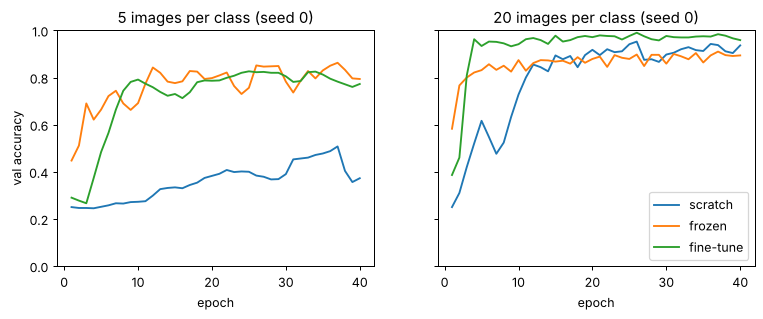

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, n_per in zip(axes, [5, 20]):
    for mode in ["scratch", "frozen", "fine-tune"]:
        ax.plot(range(1, 41), curves[(n_per, mode)], label=mode)
    ax.set_title(f"{n_per} images per class (seed 0)"); ax.set_xlabel("epoch"); ax.set_ylim(0, 1)
axes[0].set_ylabel("val accuracy"); axes[1].legend(); save_show("transfer_curves")

In [24]:
# Pitfall: freezing weights but leaving BatchNorm in train mode still changes the backbone
m, _ = make_transfer_model("frozen")
before = m.features[0][1].running_mean.clone()
m.train()                                            # forgot features.eval()
with torch.no_grad(): m(normalize(Xt20[:16]))
print("BN running_mean changed although weights are frozen:", not torch.allclose(before, m.features[0][1].running_mean))

BN running_mean changed although weights are frozen: True


🔍 **What to notice**
* Freezing trains only 260 parameters (64×4 + 4) instead of ~24,000 — that's why it resists overfitting with 5 images per class.
* Fine-tuning learns faster from the start than scratch, because it starts from useful features (see the curves).
* Discriminative learning rates gave about the same result as plain fine-tuning here (0.964 vs 0.970); they matter more for
  large pretrained backbones, where a high LR can wreck carefully learned features.
* A frozen network is **not** truly frozen if its BatchNorm layers stay in train mode — running statistics still change.

✍️ **Exercise 6:** Implement gradual unfreezing: 10 epochs head-only, then unfreeze block 3 for 10 epochs, then everything for 20.

---
## 7. Pretrained model weights and inference transforms

torchvision bundles each pretrained model with a **weights object** that records how it was trained: the dataset, the class names,
accuracy, and — crucially — the exact **inference transforms**. Use them; don't guess.

> The weights metadata below works offline. Downloading the actual weights needs internet: the last cell of this section runs the
> real ResNet-18 on our photos when the download is possible (e.g. in Google Colab), and explains itself otherwise.

In [25]:
from torchvision.models import resnet18, ResNet18_Weights
weights = ResNet18_Weights.IMAGENET1K_V1
meta = weights.meta
print("weights           :", weights)
print("trained on        :", "ImageNet-1k,", len(meta["categories"]), "classes, e.g.", meta["categories"][:4])
print("parameters        :", f"{meta['num_params']:,}")
print("reported accuracy :", meta["_metrics"]["ImageNet-1K"])
preprocess = weights.transforms()
print("\ninference transforms:\n", preprocess)

weights           : ResNet18_Weights.IMAGENET1K_V1
trained on        : ImageNet-1k, 1000 classes, e.g. ['tench', 'goldfish', 'great white shark', 'tiger shark']
parameters        : 11,689,512
reported accuracy : {'acc@1': 69.758, 'acc@5': 89.078}

inference transforms:
 ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


china (3, 427, 640) → preprocessed (3, 224, 224) | mean per channel [0.42 0.5  0.65]


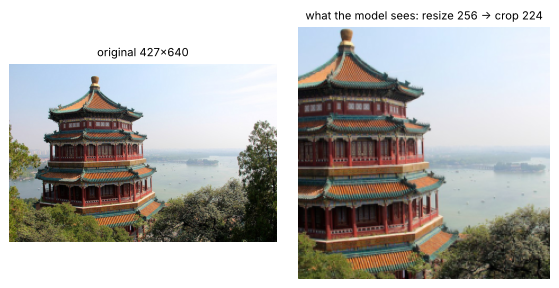

ResNet-18 architecture built (random weights): 11,689,512 parameters


In [26]:
x = preprocess(china)
print("china", tuple(china.shape), "→ preprocessed", tuple(x.shape), "| mean per channel", x.mean((1, 2)).numpy().round(2))
show([china, x * torch.tensor([.229, .224, .225]).view(3, 1, 1) + torch.tensor([.485, .456, .406]).view(3, 1, 1)],
     ["original 427×640", "what the model sees: resize 256 → crop 224"], size=3.2, name="inference_transform")
model_arch = resnet18(weights=None)
print("ResNet-18 architecture built (random weights):", f"{n_params(model_arch):,} parameters")

In [27]:
# What goes wrong with the wrong preprocessing? Use our trained source model on its own validation set
def acc_with(fn):
    source_model.eval()
    with torch.inference_mode():
        return (source_model(fn(Xsv).to(device)).argmax(1).cpu() == ysv).float().mean().item()
prep_tests = {
    "correct: normalize with training stats": lambda x: normalize(x),
    "forgot to normalize":                    lambda x: x,
    "0–255 instead of 0–1":                   lambda x: normalize(x * 255),
    "RGB ↔ BGR channels swapped":             lambda x: normalize(x.flip(1)),
    "wrong stats (ImageNet mean/std)":        lambda x: (x - torch.tensor([.485, .456, .406]).view(1, 3, 1, 1)) / torch.tensor([.229, .224, .225]).view(1, 3, 1, 1),
}
prep_res = {k: acc_with(f) for k, f in prep_tests.items()}
RESULTS["preprocessing"] = {k: round(v, 4) for k, v in prep_res.items()}
pd.Series(prep_res, name="source val accuracy").round(3)

correct: normalize with training stats    1.000
forgot to normalize                       0.801
0–255 instead of 0–1                      0.947
RGB ↔ BGR channels swapped                1.000
wrong stats (ImageNet mean/std)           0.952
Name: source val accuracy, dtype: float64

In [28]:
# Real ImageNet inference — runs where the weights can be downloaded
try:
    net = resnet18(weights=weights).eval()
    with torch.inference_mode():
        probs = net(torch.stack([preprocess(china), preprocess(flower)])).softmax(1)
    for name, p in zip(["china", "flower"], probs):
        top = p.topk(5)
        print(name, [(meta["categories"][i], round(v.item(), 3)) for v, i in zip(top.values, top.indices)])
except Exception as e:
    print("Pretrained weights could not be downloaded here:", type(e).__name__)
    print("→ Run this cell with internet access (e.g. Google Colab) to see real ImageNet top-5 predictions.")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


Pretrained weights could not be downloaded here: URLError
→ Run this cell with internet access (e.g. Google Colab) to see real ImageNet top-5 predictions.


🔍 **What to notice**
* The weights object carries everything needed to use the model correctly: classes, accuracy, and its preprocessing
  (resize to 256, centre-crop 224, ImageNet mean/std, bilinear interpolation).
* Preprocessing mistakes **don't raise errors** — they silently cost accuracy. Forgetting normalization drops our model from
  100% to about 80%; 0–255 inputs or the wrong mean/std cost about 5 points (BatchNorm absorbs part of the damage).
* Swapping RGB ↔ BGR did **nothing here** — because colours in the shapes dataset are random, colour carries no information.
  For real photos (a red stop sign, a blue sky) a channel swap is a serious bug. A test only catches the mistakes your data can reveal.
* Always call `model.eval()` and wrap inference in `torch.inference_mode()`.

✍️ **Exercise 7:** In Colab, replace `resnet18` with `efficientnet_b0` and its weights. How do the inference transforms differ?

---
## 8. Validation and class-wise evaluation

Overall accuracy hides **which** classes fail. Always look at:
* the **confusion matrix** — rows = true class, columns = predicted class
* per-class **precision** (when it says “x”, is it right?) and **recall** (does it find all the x's?)
* the actual **misclassified images** — they often reveal label errors or data problems

Validation must be **separate** from training (no near-duplicate images across splits) and **stratified** so every class is present.

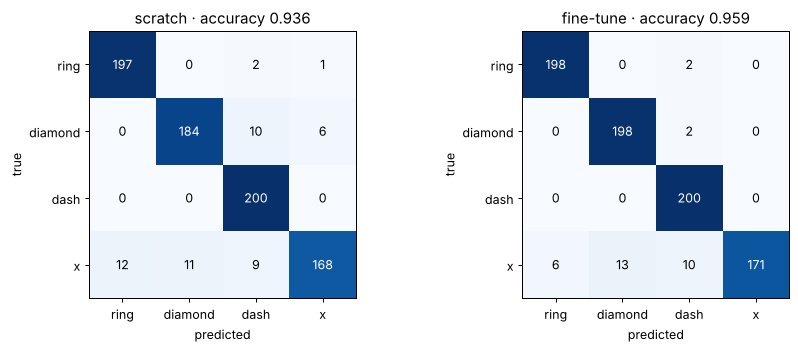

In [29]:
# Compare a scratch model and a fine-tuned model on the target task (20 per class), seed 0
models_eval = {}
for mode in ["scratch", "fine-tune"]:
    torch.manual_seed(0)
    m, kw = make_transfer_model(mode)
    train(m, Xt20, yt20, epochs=40, bs=16, seed=0, **kw)
    models_eval[mode] = m

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
reports = {}
for ax, (mode, m) in zip(axes, models_eval.items()):
    acc, pred = evaluate(m, Xtv, ytv)
    cm = confusion_matrix(ytv, pred)
    ax.imshow(cm, cmap="Blues")
    for i in range(4):
        for j in range(4): ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > 100 else "black")
    ax.set_xticks(range(4), TGT); ax.set_yticks(range(4), TGT); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title(f"{mode} · accuracy {acc:.3f}")
    reports[mode] = classification_report(ytv, pred, target_names=TGT, output_dict=True)
    RESULTS[f"cm_{mode}"] = cm.tolist()
plt.tight_layout(); save_show("confusion")

In [30]:
per_class = pd.DataFrame({(mode, metric): {c: reports[mode][c][metric] for c in TGT}
                          for mode in reports for metric in ["precision", "recall"]}).round(3)
RESULTS["per_class"] = {mode: {c: {k: round(reports[mode][c][k], 4) for k in ["precision", "recall", "f1-score"]} for c in TGT} for mode in reports}
per_class

scratch        fine-tune       
        precision recall precision recall
ring        0.943  0.985     0.971  0.990
diamond     0.944  0.920     0.938  0.990
dash        0.905  1.000     0.935  1.000
x           0.960  0.840     1.000  0.855

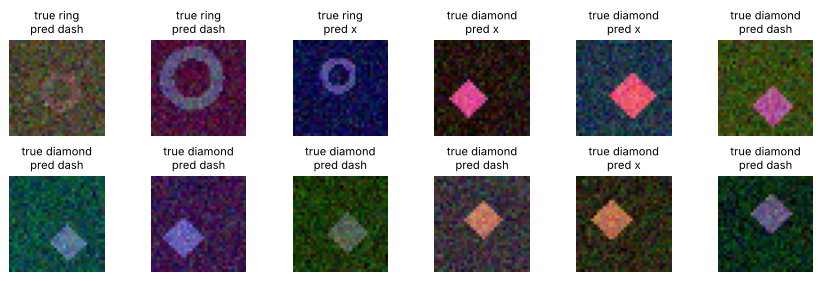

In [31]:
# Look at the mistakes of the scratch model
acc, pred = evaluate(models_eval["scratch"], Xtv, ytv)
wrong = (pred != ytv).nonzero().flatten()[:12]
show([Xtv[i] for i in wrong], [f"true {TGT[ytv[i]]}\npred {TGT[pred[i]]}" for i in wrong], cols=6, size=1.6, name="mistakes")

🔍 **What to notice**
* The confusion matrix shows *which* pairs get mixed up, not just how many errors. Here **x** is the weakest class for both models —
  confused with rings, diamonds and dashes — while dashes are always found.
* Fine-tuning fixes diamonds (recall 0.92 → 0.99) but x stays the weakest (≈0.85): a clear signal to collect or check more x examples.
* Overall accuracy (0.94 vs 0.96) hides this: per-class recall tells you where to work next.
* Looking at the mistakes is the fastest way to find out *why*: small, low-contrast or noisy shapes cause most errors.

✍️ **Exercise 8:** Compute **balanced accuracy** (mean per-class recall). When would it differ from plain accuracy?

---
## 9. GPU memory and batch-size trade-offs

Training memory ≈ **weights + gradients + optimizer state + activations (+ workspace)**.

| Item | Scales with | Size for ResNet-18 |
|---|---|---|
| Weights (float32) | model size | 11.7 M × 4 B |
| Gradients | model size | same as weights |
| Adam state (m, v) | model size | 2 × weights |
| **Activations** saved for backward | **batch size × image size** | usually the biggest part |

Ways to fit: smaller batch, **gradient accumulation**, **mixed precision** (fp16/bf16 halves activation memory), smaller images,
gradient checkpointing, a frozen backbone.

In [32]:
def activation_bytes(model, input_shape):
    # Sum of the outputs of every leaf module for one forward pass (what backward has to keep, roughly)
    total = [0]
    hooks = [m.register_forward_hook(lambda m, i, o: total.__setitem__(0, total[0] + o.numel() * o.element_size()))
             for m in model.modules() if len(list(m.children())) == 0]
    with torch.no_grad(): model(torch.zeros(input_shape))
    for h in hooks: h.remove()
    return total[0]

net = resnet18(weights=None)
p_bytes = n_params(net) * 4
act_1 = activation_bytes(net, (1, 3, 224, 224))
rows = []
for bs in [1, 8, 16, 32, 64, 128, 256]:
    act = act_1 * bs
    rows.append({"batch size": bs, "weights+grads+Adam (GB)": 4 * p_bytes / 1e9,
                 "activations fp32 (GB)": act / 1e9, "total fp32 (GB)": (4 * p_bytes + act) / 1e9,
                 "total with fp16/bf16 activations (GB)": (4 * p_bytes + act / 2) / 1e9})
mem = pd.DataFrame(rows).set_index("batch size").round(2)
RESULTS["memory"] = mem.reset_index().to_dict(orient="list")
print(f"activations for ONE 224×224 image: {act_1/1e6:.1f} MB")
mem

activations for ONE 224×224 image: 29.9 MB


,weights+grads+Adam (GB),activations fp32 (GB),total fp32 (GB),total with fp16/bf16 activations (GB)
batch size,,,,
1,0.19,0.03,0.22,0.20
8,0.19,0.24,0.43,0.31
16,0.19,0.48,0.67,0.43
32,0.19,0.96,1.14,0.67
64,0.19,1.91,2.10,1.14
128,0.19,3.83,4.02,2.10
256,0.19,7.66,7.84,4.02


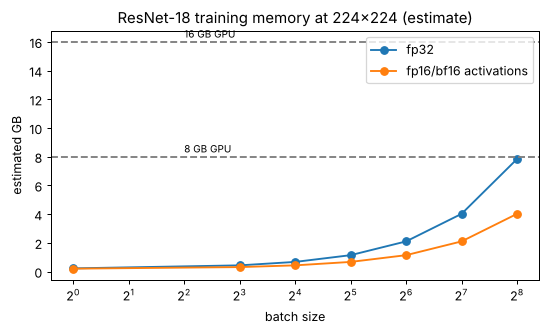

In [33]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(mem.index, mem["total fp32 (GB)"], "o-", label="fp32")
ax.plot(mem.index, mem["total with fp16/bf16 activations (GB)"], "o-", label="fp16/bf16 activations")
for gb, lbl in [(8, "8 GB GPU"), (16, "16 GB GPU")]:
    ax.axhline(gb, ls="--", color="gray"); ax.text(4, gb + .3, lbl, fontsize=8)
ax.set_xscale("log", base=2); ax.set_xlabel("batch size"); ax.set_ylabel("estimated GB"); ax.legend()
ax.set_title("ResNet-18 training memory at 224×224 (estimate)"); save_show("memory_vs_batch")

In [34]:
# Gradient accumulation: 4 micro-batches of 8 give the same gradient as one batch of 32
torch.manual_seed(0)
m1 = SmallCNN(4); m2 = copy.deepcopy(m1)
xb, yb = normalize(Xs[:32]), ys[:32]
m1.eval(); m2.eval()                                   # eval mode so BatchNorm uses the same statistics in both
F.cross_entropy(m1(xb), yb).backward()
for i in range(0, 32, 8):
    (F.cross_entropy(m2(xb[i:i+8]), yb[i:i+8]) / 4).backward()      # divide by the number of micro-batches
g1 = torch.cat([p.grad.flatten() for p in m1.parameters()]); g2 = torch.cat([p.grad.flatten() for p in m2.parameters()])
print("max gradient difference, batch 32 vs 4×8 accumulated:", f"{(g1 - g2).abs().max().item():.2e}")

max gradient difference, batch 32 vs 4×8 accumulated: 5.07e-07


In [35]:
# Throughput vs batch size on this machine (images per second, one training epoch on 2,048 source images)
speed = {}
for bs in [8, 32, 128, 512]:
    torch.manual_seed(0); m = SmallCNN(4)
    t0 = time.time(); train(m, Xs[:2048], ys[:2048], epochs=1, bs=bs); dt = time.time() - t0
    speed[bs] = 2048 / dt
RESULTS["throughput"] = {str(k): round(v) for k, v in speed.items()}
print({k: f"{v:,.0f} img/s" for k, v in speed.items()}, f"(on {device}, {torch.get_num_threads()} threads)")
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()
    m = resnet18(weights=None).cuda(); opt = torch.optim.Adam(m.parameters())
    loss = m(torch.randn(32, 3, 224, 224, device="cuda")).sum(); loss.backward(); opt.step()
    print("measured peak GPU memory, ResNet-18, batch 32:", f"{torch.cuda.max_memory_allocated()/1e9:.2f} GB")

{8: '1,940 img/s', 32: '3,396 img/s', 128: '4,047 img/s', 512: '3,478 img/s'} (on cpu, 2 threads)


🔍 **What to notice**
* Weights, gradients and Adam state for ResNet-18 are fixed (~0.19 GB); **activations grow linearly with batch size** and dominate
  quickly. Half-precision activations roughly halve that part.
* Gradient accumulation reproduces the big-batch gradient (difference ~5e-7, just float rounding) using a quarter of the activation memory —
  in train mode, BatchNorm then sees smaller batches, a minor difference.
* Bigger batches process more images per second (until memory or compute is saturated), but very large batches often need a higher
  learning rate and can generalise slightly worse. Common practice: the largest batch that fits, with LR scaled accordingly.
* On a GPU, `torch.cuda.max_memory_allocated()` measures the real peak; the estimate ignores cuDNN workspace and fragmentation.

✍️ **Exercise 9:** Repeat the memory table for 128×128 images. How does memory scale with image side length?

---
## 10. Dataset licensing and image privacy

Images come with **rights** and often show **people**. Before training — and especially before sharing a model — check:

| Licence | Can you train on it? | Can you use the model commercially? |
|---|---|---|
| CC0 / public domain | yes | yes |
| CC BY | yes, with attribution | yes, with attribution |
| CC BY-SA | yes | yes, but share-alike may apply to derived data |
| CC BY-NC | yes for research | **no** commercial use |
| “Research only” terms (many academic datasets) | research only | usually **no** |
| Scraped, no licence | unclear — **ask a lawyer** | high risk |

(Not legal advice — terms differ by dataset and country.)

**Privacy:** faces, licence plates, house numbers, documents and screens can identify people. Photos also hide **metadata**
(EXIF: GPS location, time, camera serial). Data protection laws such as the EU GDPR treat identifiable images as personal data.

In [36]:
# A minimal dataset card, and filtering images by licence before training
records = pd.DataFrame([
    {"file": "img_001.jpg", "source": "own photos",        "license": "CC0",      "has_people": False, "consent": None},
    {"file": "img_002.jpg", "source": "Wikimedia Commons", "license": "CC BY 4.0","has_people": False, "consent": None},
    {"file": "img_003.jpg", "source": "Flickr",            "license": "CC BY-NC", "has_people": True,  "consent": False},
    {"file": "img_004.jpg", "source": "web scrape",        "license": "unknown",  "has_people": True,  "consent": False},
    {"file": "img_005.jpg", "source": "volunteer study",   "license": "CC BY 4.0","has_people": True,  "consent": True},
])
COMMERCIAL_OK = {"CC0", "CC BY 4.0"}
records["use_for_commercial_model"] = records.license.isin(COMMERCIAL_OK) & (~records.has_people | (records.consent == True))
records

,file,source,license,has_people,consent,use_for_commercial_model
0,img_001.jpg,own photos,CC0,False,None,True
1,img_002.jpg,Wikimedia Commons,CC BY 4.0,False,None,True
2,img_003.jpg,Flickr,CC BY-NC,True,False,False
3,img_004.jpg,web scrape,unknown,True,False,False
4,img_005.jpg,volunteer study,CC BY 4.0,True,True,True


In [37]:
# EXIF metadata can reveal where a photo was taken — strip it before sharing
from PIL import Image
pil = Image.fromarray(load_sample_image("flower.jpg"))
exif = Image.Exif()
exif[0x010F] = "ExampleCam"                     # camera make
exif[0x0132] = "2026:11:25 10:30:00"            # date/time
gps = {1: "N", 2: (31.0, 31.0, 0.0), 3: "E", 4: (74.0, 21.0, 0.0)}   # a made-up GPS position
exif[0x8825] = gps
buf = io.BytesIO(); pil.save(buf, format="JPEG", exif=exif); buf.seek(0)
with_exif = Image.open(buf)
print("EXIF in shared file:", {k: v for k, v in with_exif.getexif().items() if k != 0x8825}, "| GPS block:", dict(with_exif.getexif().get_ifd(0x8825)))

clean_buf = io.BytesIO(); Image.fromarray(np.array(with_exif)).save(clean_buf, format="JPEG"); clean_buf.seek(0)
print("EXIF after stripping:", dict(Image.open(clean_buf).getexif()))

EXIF in shared file: {306: '2026:11:25 10:30:00', 271: 'ExampleCam'} | GPS block: {1: 'N', 2: (31.0, 31.0, 0.0), 3: 'E', 4: (74.0, 21.0, 0.0)}
EXIF after stripping: {}


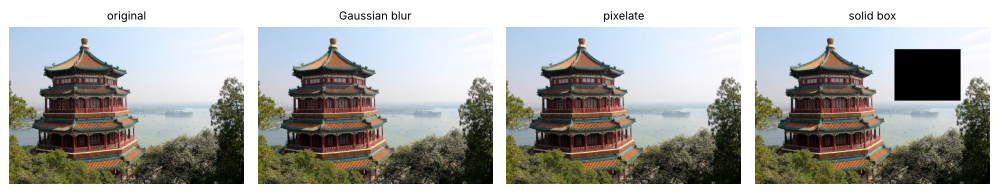

In [38]:
# Anonymise a sensitive region (stand-in for a face or licence plate): blur vs pixelate
region = (slice(None), slice(60, 200), slice(380, 560))
blurred = china.clone()
blurred[region] = v2.functional.gaussian_blur(china[region], kernel_size=31, sigma=12)
pixelated = china.clone()
small = F.interpolate(china[region].unsqueeze(0), scale_factor=1/14, mode="area")
pixelated[region] = F.interpolate(small, size=china[region].shape[1:], mode="nearest")[0]
boxed = china.clone(); boxed[region] = 0.0
show([china, blurred, pixelated, boxed], ["original", "Gaussian blur", "pixelate", "solid box"], cols=4, size=2.8, name="anonymise")

🔍 **What to notice**
* A simple dataset card makes licence and consent decisions **explicit and checkable** — only 3 of the 5 example records may go into a commercial model (img_005 shows people, but they consented).
* The EXIF block carried a camera name, a timestamp and GPS coordinates; re-saving the pixels alone removed all of it.
* Blur and pixelation **can sometimes be reversed or recognised** by models; a solid box is the safest for faces and plates.
* Other good practice: collect only what you need, keep a record of where each image came from, honour deletion requests,
  take extra care with children and medical images, and document all of this in the model card.

✍️ **Exercise 10:** Add a `retention_until` date and a `source_url` column to the dataset card, and write a check that fails if any
image lacks a licence.

In [39]:
Path("results.json").write_text(json.dumps(RESULTS, indent=1, default=float))
print("saved results.json and", len(list(FIGS.glob("*.png"))), "figures in figs/")

saved results.json and 18 figures in figs/


---
## Summary

| Topic | Remember |
|---|---|
| Image tensors | CHW float32 in [0,1]; batches are NCHW; normalize per channel with **training** statistics |
| Convolution | `out = ⌊(n + 2p − d(k−1) − 1)/s⌋ + 1`; weight sharing → far fewer parameters than dense layers |
| Feature hierarchy | edges → textures → parts → objects; receptive field grows with depth |
| Augmentation | training only, label-preserving; big gains with little data |
| Transfer vs scratch | little data → transfer wins by a lot; fine-tuning usually best once you have some data |
| Frozen vs fine-tune | freeze for tiny data; fine-tune with small/discriminative LR; freeze BatchNorm stats too |
| Pretrained weights | use `weights.transforms()` exactly; wrong preprocessing fails silently |
| Class-wise evaluation | confusion matrix, per-class precision/recall, look at the mistakes |
| GPU memory | activations scale with batch × image size; accumulate gradients, use mixed precision |
| Licensing & privacy | check licences and consent, strip EXIF, anonymise people, document everything |